# step_1_Importing The Required Libraries

In [ ]:

# Importing The Required Libraries
# Import NumPy for numerical operations and array handling
import numpy as np

# Import Matplotlib for creating graphs and visualizations
import matplotlib.pyplot as plt

# Import Seaborn for attractive statistical visualizations such as heatmaps
import seaborn as sns

# Import TensorFlow for building and training deep-learning models
import tensorflow as tf

# Import Sequential to create a layer-by-layer neural-network model
from tensorflow.keras import Sequential

# Import different layers required to build and improve the CNN model
from tensorflow.keras.layers import (
    Input,
    Dense,
    Flatten,
    Conv2D,
    MaxPooling2D,
    Dropout,
    BatchNormalization,
    RandomRotation,
    RandomZoom,
    RandomTranslation
)

# Import confusion_matrix to compare actual and predicted classes
from sklearn.metrics import (
    confusion_matrix,

    # Import classification_report to calculate precision, recall, and F1-score
    classification_report
)

# Display the installed TensorFlow version
print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.20.0



**Dropout** randomly turns off some neurons during training.

For example, Dropout(0.5) temporarily disables 50% of neurons in each training step.

**Why do we use it?**

It prevents the model from depending too much on particular neurons.
It **reduces overfitting.**
It improves performance on unseen test images.

It works only during training, not during prediction.

**batch_normalization**

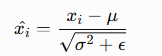
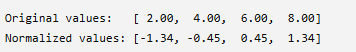
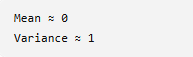

*In a CNN, Batch Normalization generally normalizes the values of each channel across the batch and spatial dimensions.*

(((**spatial dimensions = Height*Width.**)))

**RandomRotation**

**Why?**
The object may appear slightly tilted in a real-world image. This teaches the model to identify the object even when its angle changes.

**RandomZoom**
Original image which looks Closer or farther-looking image
**Why?**
An object may appear at different distances or sizes. This teaches the CNN to recognize it regardless of its apparent size.

**RandomTranslation**

It randomly shifts an image horizontally or vertically.

**Why?**

The object will not always be perfectly centred. This teaches the model to recognize it at different positions.

**RandomRotation**, **RandomZoom**, and **RandomTranslation** are called **data-augmentation layers**. They generate slightly modified versions of the training images, helping the model generalize to unseen images.

#Step__2: Loading the MNIST Dataset

In [ ]:
# Step__2: Loading the MNIST Dataset

(x_train, y_train), (x_test, y_test) = (
    tf.keras.datasets.mnist.load_data()
)

print("Training images shape:", x_train.shape)
print("Training labels shape:", y_train.shape)

print("Testing images shape:", x_test.shape)
print("Testing labels shape:", y_test.shape)

print("First training label:", y_train[0])  ## Displays the correct label of the first training image

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training images shape: (60000, 28, 28)
Training labels shape: (60000,)
Testing images shape: (10000, 28, 28)
Testing labels shape: (10000,)
First training label: 5


## step__3 Displaying the first training image

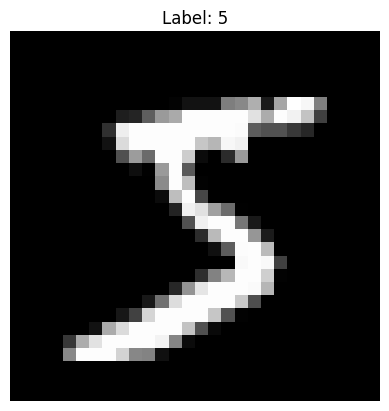

In [ ]:
# step__3 Displaying the first training image
plt.imshow(x_train[0], cmap="gray")

# Showing its correct label as the title
plt.title(f"Label: {y_train[0]}")

# Hide axis values for better visualization
plt.axis("off")                                # Hides x-axis and y-axis

# Display the image
plt.show()

# step__4 Create a figure with a width of 10 inches and a height of 5 inches

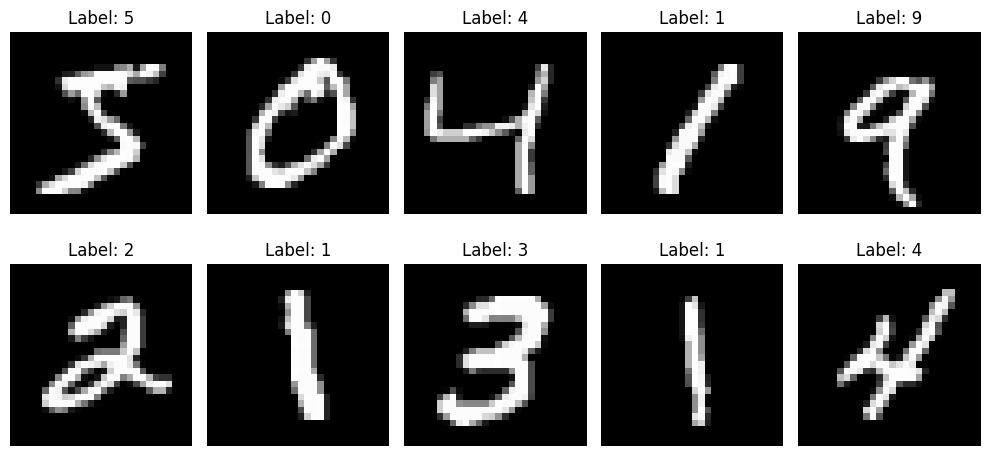

In [ ]:
# step__4 Create a figure with a width of 10 inches and a height of 5 inches
plt.figure(figsize=(10, 5))

# Run the loop 10 times to display the first 10 training images
for index in range(10):

    # Create a 2-row and 5-column grid and select the current subplot
    # index + 1 is used because subplot numbering starts from 1
    plt.subplot(2, 5, index + 1)

    # Display the training image at the current index
    plt.imshow(
        x_train[index],  # Select the image using the current index
        cmap="gray"      # Display the image using a grayscale colour map
    )

    # Display the correct image label as the subplot title
    plt.title(f"Label: {y_train[index]}")

    # Hide the x-axis, y-axis, tick marks and axis labels
    plt.axis("off")

# Automatically adjust spacing to prevent subplot elements from overlapping
plt.tight_layout()

# Display the complete figure containing all 10 images
plt.show()

#
# Step__5: Checking the  Pixel Values of first image ie number-5

In [ ]:

# Step__5: Checking the  Pixel Values of first image ie number-5
print("Minimum pixel value:", x_train.min())
print("Maximum pixel value:", x_train.max())

print("\nFirst image pixel matrix:")
print(x_train[0])

Minimum pixel value: 0
Maximum pixel value: 255

First image pixel matrix:
[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   3  18  18  18 126 136
  175  26 166 255 247 127   0   0   0   0]
 [  0   0   0   0   0   0   0   0  30  36  94 154 170 253 253 253 253 253
  225 172 253 242 195  64   0   0   0   0]
 [  0   0   0   0   0   0   0  49 238 253 253 253 253 253 253 253 253 251
   93  82  82  56  39   0   0   

# Step__6: Normalizing all the Pixel Values

In [ ]:

# Step__6: Normalizing all the Pixel Values

# Convert integer pixel values into float values
x_train = x_train.astype("float32")
x_test = x_test.astype("float32")

# Convert range from 0-255 to 0-1
x_train = x_train / 255.0
x_test = x_test / 255.0

print("Minimum normalized value:", x_train.min())
print("Maximum normalized value:", x_train.max())

Minimum normalized value: 0.0
Maximum normalized value: 1.0


**Why is normalization used?**

It keeps input values in a smaller range.

It helps the model train faster.

It improves numerical stability.

It prevents large pixel values from dominating the learning process.

It is performed before data enters the neural network.

**Why is Batch Normalization used?**

It makes training faster and more stable.

It controls changes in layer activations.

It allows the use of a higher learning rate.

It can provide a small regularization effect.

It is applied inside the neural network.

**In a CNN, it generally normalizes each channel using values across the batch, height and width dimensions.**

## Step__7: Add Channel Dimension

In [ ]:
# Step__7: Add Channel Dimension
x_train_cnn = np.expand_dims(x_train, axis=-1)
x_test_cnn = np.expand_dims(x_test, axis=-1)

print("CNN training shape:", x_train_cnn.shape)
print("CNN testing shape:", x_test_cnn.shape)



CNN training shape: (60000, 28, 28, 1)
CNN testing shape: (10000, 28, 28, 1)


**We are not changing the pixel values; we are only telling TensorFlow that these are grayscale images with one channel.**

##step__8 Applying Algorithm 1: Artificial Neural Network  Baseline Model


In [ ]:
#step__8 Applying Algorithm 1: Artificial Neural Network
#Creating a Baseline Model

ann_model = Sequential([
    # Input image shape: (28, 28)
    Input(shape=(28, 28)),

    # Convert 2D image into a 1D vector
    # (28, 28) → (784)
    Flatten(),

    # Hidden layer
    Dense(
        units=128,
        activation="relu"
    ),

    Dropout(0.3),

    # Output layer
    # 10 neurons for digits 0 to 9
    Dense(
        units=10,
        activation="softmax"
    )
])

ann_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

**Model: "sequential"**---It means the layers are connected sequentially—output from one layer becomes input to the next layer:

**Input - Flatten - Dense - Dropout - Dense**

**Parameter calculation:** internal layer

*Weights=784*128=100,352*

Each of the 128 neurons also has one bias:

*Biases=128*

Therefore:

*100,352+128=100,480*

**output_layer**

**Parameter calculation:**

Weights=128*10=1,280

Biases=10

Total=1,280+10=1,290

**With softmax, these 10 outputs become class probabilities.**

**6. Total parameters**---- **101,770**

It is the **sum of all layer parameters**:

**100,480+1,290=101,770**

Flatten and Dropout contribute zero parameters.

** Trainable parameters**
Trainable params: 101,770

These **weights and biases are updated** during training **through backpropagation** and the optimizer.

 **Non-trainable parameters**
Non-trainable params: 0

This model has **no frozen parameters**. Therefore, all 101,770 parameters can be updated during training.

**Model size**= 397.54 KB

Each parameter normally uses 32-bit floating-point storage:

**101,770*4 bytes=407,080 bytes**

Converting bytes to KB:

**407,080÷1024**   ≈     **397.54 KB**



#step__9 Compile and Train ANN


In [ ]:
#step__9 Compile and Train ANN

ann_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",   #loss function used for multiclass classification when the correct labels are integers.
    metrics=["accuracy"]
)

ann_history = ann_model.fit(
    x_train,
    y_train,
    validation_split=0.2,  #Training data   = 80% of 60,000 = 48,000 images
                            #Validation data = 20% of 60,000 = 12,000 images
    epochs=10,
    batch_size=64,
    verbose=1              # Displays the training progress bar and metrics for every epoch
)

ann_test_loss, ann_test_accuracy = ann_model.evaluate(
    x_test,
    y_test,
    verbose=0              ## Shows a progress bar and metrics
)

print("ANN Test Loss:", ann_test_loss)
print("ANN Test Accuracy:", ann_test_accuracy)

Epoch 1/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - accuracy: 0.8831 - loss: 0.4013 - val_accuracy: 0.9493 - val_loss: 0.1839
Epoch 2/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9416 - loss: 0.2005 - val_accuracy: 0.9598 - val_loss: 0.1383
Epoch 3/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9549 - loss: 0.1543 - val_accuracy: 0.9635 - val_loss: 0.1195
Epoch 4/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9615 - loss: 0.1279 - val_accuracy: 0.9693 - val_loss: 0.1008
Epoch 5/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9668 - loss: 0.1107 - val_accuracy: 0.9703 - val_loss: 0.0968
Epoch 6/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9694 - loss: 0.0981 - val_accuracy: 0.9732 - val_loss: 0.0884
Epoch 7/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9731 - loss: 0.0877 - val_accuracy: 0.9737 - val_loss: 0.0870
Epoch 8/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9749 - loss: 0.0789 - val_accuracy: 0.

*Input layer* --- Input(shape=(28, 28))

*Flatten Converts* -- 28*28 into 784 values

*Hidden layer* --- Dense(128)

*Dropout* --- Regularization operation, not usually counted as a hidden neuron layer

*Output layer*---- Dense(10)

# Step 10: Apply a Basic Convolutional Neural Network

In [ ]:
# Step_10: Apply a Basic Convolutional Neural Network

basic_cnn_model = Sequential([

    # Input layer
    # Height = 28, Width = 28, Channels = 1
    Input(shape=(28, 28, 1)),

    # First convolutional layer
    # 32 filters generate 32 feature maps
    # Input shape:  (28, 28, 1)
    # Output shape: (26, 26, 32)
    Conv2D(
        filters=32,
        kernel_size=(3, 3),
        activation="relu",
        padding="valid"  # No padding is added
    ),

    # First Max Pooling layer
    # Reduces height and width by half
    # Shape: (26, 26, 32) → (13, 13, 32)
    MaxPooling2D(
        pool_size=(2, 2)
    ),

    # Max Pooling example:
    #
    # Input:
    #
    # 1  3 | 2  4
    # 5  6 | 1  2
    # ----- | -----
    # 7  2 | 8  1
    # 3  4 | 2  9
    #
    # Block 1: max(1, 3, 5, 6) = 6
    # Block 2: max(2, 4, 1, 2) = 4
    # Block 3: max(7, 2, 3, 4) = 7
    # Block 4: max(8, 1, 2, 9) = 9
    #
    # Output:
    #
    # 6  4
    # 7  9
    #
    # Input shape:  4 × 4
    # Output shape: 2 × 2

    # Second convolutional layer
    # 64 filters generate 64 feature maps
    # Shape: (13, 13, 32) → (11, 11, 64)
    Conv2D(
        filters=64,
        kernel_size=(3, 3),
        activation="relu",
        padding="valid"  # No padding is added
    ),

    # Second Max Pooling layer
    # Shape: (11, 11, 64) → (5, 5, 64)
    # 11 cannot be divided evenly by 2, so the extra row and column are ignored
    MaxPooling2D(
        pool_size=(2, 2)
    ),

    # Convert all 5 × 5 × 64 feature maps into a 1D vector
    # 5 × 5 × 64 = 1600 values
    Flatten(),

    # Hidden fully connected layer containing 128 neurons
    Dense(
        units=128,
        activation="relu"
    ),

    # Randomly disable 30% of neurons during training
    # This helps reduce overfitting
    Dropout(0.3),

    # Output layer containing 10 neurons for digits 0–9
    # Softmax converts outputs into class probabilities
    Dense(
        units=10,
        activation="softmax"
    )
])

# Display all layers, output shapes and parameter counts
basic_cnn_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

#step__11_Compile and Train Basic CNN

In [ ]:
#step__11_Compile and Train Basic CNN

basic_cnn_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

basic_cnn_history = basic_cnn_model.fit(
    x_train_cnn,
    y_train,
    validation_split=0.2,
    epochs=10,
    batch_size=64,
    verbose=1
)

basic_cnn_loss, basic_cnn_accuracy = basic_cnn_model.evaluate(
    x_test_cnn,
    y_test,
    verbose=0       ## Shows a progress bar and metrics
)

print("Basic CNN Test Loss:", basic_cnn_loss)
print("Basic CNN Test Accuracy:", basic_cnn_accuracy)

Epoch 1/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.9305 - loss: 0.2253 - val_accuracy: 0.9786 - val_loss: 0.0715
Epoch 2/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9775 - loss: 0.0726 - val_accuracy: 0.9854 - val_loss: 0.0487
Epoch 3/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9836 - loss: 0.0511 - val_accuracy: 0.9868 - val_loss: 0.0436
Epoch 4/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.9877 - loss: 0.0400 - val_accuracy: 0.9887 - val_loss: 0.0383
Epoch 5/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9891 - loss: 0.0339 - val_accuracy: 0.9895 - val_loss: 0.0355
Epoch 6/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9909 - loss: 0.0278 - val_accuracy: 0.9873 - val_loss: 0.0459
Epoch 7/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9927 - loss: 0.0231 - val_accuracy: 0.9904 - val_loss: 0.0384
Epoch 8/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9933 - loss: 0.0202 - val_accuracy: 0.

In [ ]:
# step__12 Improved CNN with Batch Normalization
improved_cnn_model = Sequential([
    Input(shape=(28, 28, 1)),


    # Convolution Block 1
    # padding="same" keeps height and width unchanged
    # Shape: (28, 28, 1) → (28, 28, 32)
    Conv2D(
        filters=32,
        kernel_size=(3, 3),
        padding="same",    #same adds pixels, usually zeros, around the input
        activation="relu"
    ),

    # Normalize activations
    BatchNormalization(),

    # Shape remains: (28, 28, 32)
    Conv2D(
        filters=32,
        kernel_size=(3, 3),
        padding="same",
        activation="relu"
    ),

    BatchNormalization(),

    # Shape: (28, 28, 32) → (14, 14, 32)
    MaxPooling2D(pool_size=(2, 2)),

    Dropout(0.25),

    # --------------------------------------------------------
    # Convolution Block 2
    # --------------------------------------------------------

    # Shape: (14, 14, 32) → (14, 14, 64)
    Conv2D(
        filters=64,
        kernel_size=(3, 3),
        padding="same",
        activation="relu"
    ),

    BatchNormalization(),

    # Shape remains: (14, 14, 64)
    Conv2D(
        filters=64,
        kernel_size=(3, 3),
        padding="same",
        activation="relu"
    ),

    BatchNormalization(),

    # Shape: (14, 14, 64) → (7, 7, 64)
    MaxPooling2D(pool_size=(2, 2)),

    Dropout(0.25),

    # --------------------------------------------------------
    # Classification Block
    # --------------------------------------------------------

    # (7, 7, 64) → 3136
    Flatten(),

    Dense(
        units=128,
        activation="relu"
    ),

    BatchNormalization(),

    Dropout(0.5),

    Dense(
        units=10,
        activation="softmax"
    )
])

improved_cnn_model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 28, 28, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 28, 28, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 28, 28, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 14, 14, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │       401,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 469,098 (1.79 MB)

 Trainable params: 468,458 (1.79 MB)

 Non-trainable params: 640 (2.50 KB)

# step__12 Improved CNN with Batch Normalization

In [ ]:
# Compile Improved CNN


improved_cnn_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Step 13: Create Training Callbacks

In [ ]:
# Step 13: Create Training Callbacks
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",

    # Stop if validation loss does not improve for 3 epochs
    patience=3,

    # Restore weights from the best epoch
    restore_best_weights=True
)

reduce_learning_rate = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",

    # New learning rate = old learning rate × 0.5
    factor=0.5,

    # Reduce after two epochs without improvement
    patience=2,

    # Learning rate will not go below this value
    min_lr=0.00001
)

# Step 14: Train Improved CNN

In [ ]:
# Step 14: Train Improved CNN
improved_cnn_history = improved_cnn_model.fit(
    x_train_cnn,
    y_train,
    validation_split=0.2,
    epochs=20,
    batch_size=64,

    callbacks=[
        early_stopping,
        reduce_learning_rate
    ],

    verbose=1
)

improved_cnn_loss, improved_cnn_accuracy = (
    improved_cnn_model.evaluate(
        x_test_cnn,
        y_test,
        verbose=0
    )
)

print("Improved CNN Test Loss:", improved_cnn_loss)
print("Improved CNN Test Accuracy:", improved_cnn_accuracy)

Epoch 1/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 15s 9ms/step - accuracy: 0.9423 - loss: 0.1885 - val_accuracy: 0.9858 - val_loss: 0.0471 - learning_rate: 0.0010
Epoch 2/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.9789 - loss: 0.0689 - val_accuracy: 0.9868 - val_loss: 0.0447 - learning_rate: 0.0010
Epoch 3/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 10s 7ms/step - accuracy: 0.9833 - loss: 0.0544 - val_accuracy: 0.9888 - val_loss: 0.0360 - learning_rate: 0.0010
Epoch 4/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.9863 - loss: 0.0451 - val_accuracy: 0.9908 - val_loss: 0.0296 - learning_rate: 0.0010
Epoch 5/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.9879 - loss: 0.0395 - val_accuracy: 0.9901 - val_loss: 0.0324 - learning_rate: 0.0010
Epoch 6/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.9887 - loss: 0.0350 - val_accuracy: 0.9917 - val_loss: 0.0272 - learning_rate: 0.0010
Epoch 7/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.9893 - loss: 0.0332 

## step__5 Algorithm 4: CNN with Data Augmentation

In [ ]:

# Algorithm 4: CNN with Data Augmentation
data_augmentation = Sequential([
    # Rotate image slightly
    RandomRotation(factor=0.08),

    # Zoom image slightly
    RandomZoom(
        height_factor=0.1,
        width_factor=0.1
    ),

    # Move image slightly horizontally or vertically
    RandomTranslation(
        height_factor=0.1,
        width_factor=0.1
    )
], name="data_augmentation")

## step_16__Build CNN with Data Augmentation

In [ ]:
# Build CNN with Data Augmentation
augmented_cnn_model = Sequential([
    Input(shape=(28, 28, 1)),

    # Augmentation is active only during training
    data_augmentation,

    # Convolution Block 1

    Conv2D(
        filters=32,
        kernel_size=(3, 3),
        padding="same",
        activation="relu"
    ),

    BatchNormalization(),

    Conv2D(
        filters=32,
        kernel_size=(3, 3),
        padding="same",
        activation="relu"
    ),

    MaxPooling2D(pool_size=(2, 2)),

    Dropout(0.25),

  # Convolution Block 2


    Conv2D(
        filters=64,
        kernel_size=(3, 3),
        padding="same",
        activation="relu"
    ),

    BatchNormalization(),

    Conv2D(
        filters=64,
        kernel_size=(3, 3),
        padding="same",
        activation="relu"
    ),

    MaxPooling2D(pool_size=(2, 2)),

    Dropout(0.25),

    # Classification


    Flatten(),

    Dense(
        units=128,
        activation="relu"
    ),

    Dropout(0.5),

    Dense(
        units=10,
        activation="softmax"
    )
])

augmented_cnn_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

augmented_cnn_model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 28, 28, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 28, 28, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 14, 14, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 128)            │       401,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 468,202 (1.79 MB)

 Trainable params: 468,010 (1.79 MB)

 Non-trainable params: 192 (768.00 B)

## step_17__Train CNN with Data Augmentation

In [ ]:

# Train CNN with Data Augmentation
augmented_cnn_history = augmented_cnn_model.fit(
    x_train_cnn,
    y_train,
    validation_split=0.2,
    epochs=20,
    batch_size=64,

    callbacks=[
        early_stopping,
        reduce_learning_rate
    ],

    verbose=1
)

augmented_cnn_loss, augmented_cnn_accuracy = (
    augmented_cnn_model.evaluate(
        x_test_cnn,
        y_test,
        verbose=0
    )
)

print("Augmented CNN Test Loss:", augmented_cnn_loss)
print("Augmented CNN Test Accuracy:", augmented_cnn_accuracy)

Epoch 1/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 16s 13ms/step - accuracy: 0.5208 - loss: 1.3000 - val_accuracy: 0.9532 - val_loss: 0.1704 - learning_rate: 0.0010
Epoch 2/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 10s 13ms/step - accuracy: 0.7992 - loss: 0.5822 - val_accuracy: 0.9736 - val_loss: 0.0914 - learning_rate: 0.0010
Epoch 3/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 9s 12ms/step - accuracy: 0.9060 - loss: 0.2958 - val_accuracy: 0.9862 - val_loss: 0.0497 - learning_rate: 5.0000e-04
Augmented CNN Test Loss: 0.16517475247383118
Augmented CNN Test Accuracy: 0.9523000121116638


## Step 18: Function to Plot Accuracy and Loss

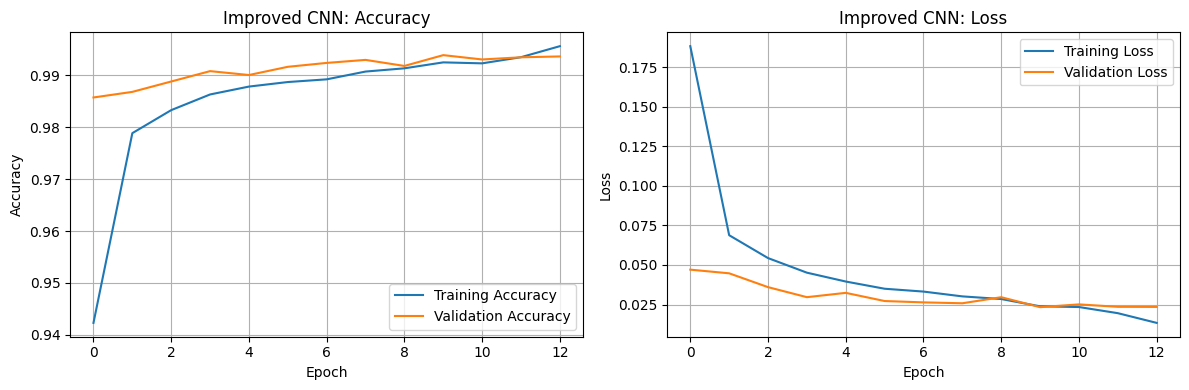

In [ ]:

# Step 18: Function to Plot Accuracy and Loss


def plot_training_history(history, model_name):

    plt.figure(figsize=(12, 4))

    # Accuracy graph


    plt.subplot(1, 2, 1)

    plt.plot(
        history.history["accuracy"],
        label="Training Accuracy"
    )

    plt.plot(
        history.history["val_accuracy"],
        label="Validation Accuracy"
    )

    plt.title(f"{model_name}: Accuracy")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.legend()
    plt.grid()


    # Loss graph


    plt.subplot(1, 2, 2)

    plt.plot(
        history.history["loss"],
        label="Training Loss"
    )

    plt.plot(
        history.history["val_loss"],
        label="Validation Loss"
    )

    plt.title(f"{model_name}: Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()
    plt.grid()

    plt.tight_layout()
    plt.show()


# Plot a model's training results
plot_training_history(
    improved_cnn_history,
    "Improved CNN"
)

# Step__20: Compare Model Accuracies

ANN: 97.81%
Basic CNN: 99.05%
Improved CNN: 99.38%
Augmented CNN: 95.23%


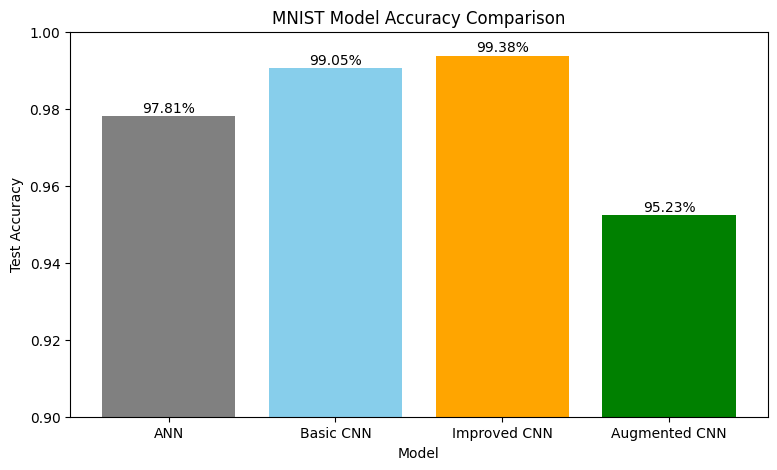

In [ ]:

# Step__20: Compare Model Accuracies


model_names = [
    "ANN",
    "Basic CNN",
    "Improved CNN",
    "Augmented CNN"
]

test_accuracies = [
    ann_test_accuracy,
    basic_cnn_accuracy,
    improved_cnn_accuracy,
    augmented_cnn_accuracy
]

for name, accuracy in zip(model_names, test_accuracies):
    print(f"{name}: {accuracy * 100:.2f}%")

plt.figure(figsize=(9, 5))

bars = plt.bar(
    model_names,
    test_accuracies,
    color=["gray", "skyblue", "orange", "green"]
)

plt.title("MNIST Model Accuracy Comparison")
plt.xlabel("Model")
plt.ylabel("Test Accuracy")
plt.ylim(0.90, 1.0)

for bar, accuracy in zip(bars, test_accuracies):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        accuracy + 0.001,
        f"{accuracy * 100:.2f}%",
        ha="center"
    )

plt.show()

# Step 21: Generating Confusion Matrix

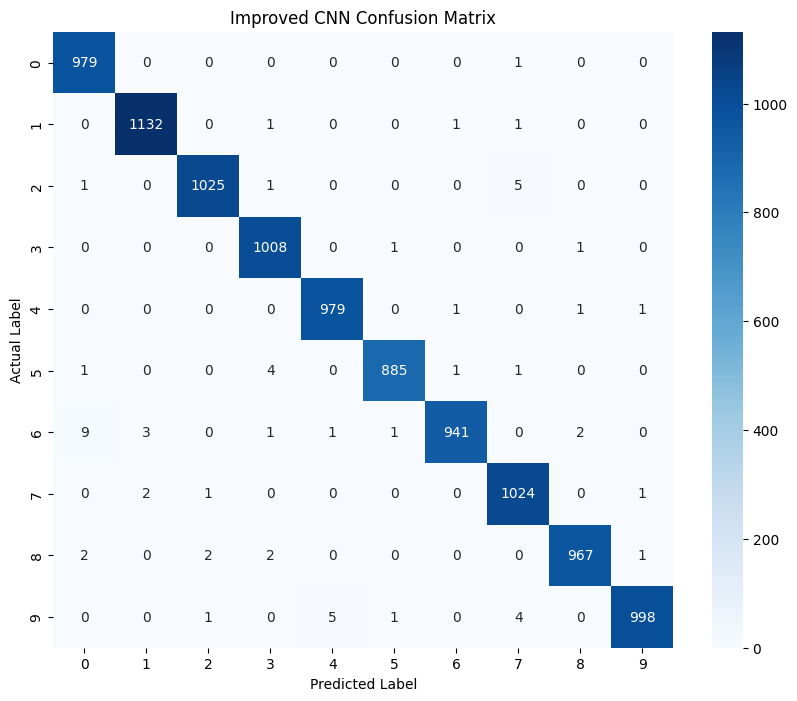

In [ ]:

#  Generate Confusion Matrix


# Get probability for every class
prediction_probabilities = improved_cnn_model.predict(
    x_test_cnn,
    verbose=0
)

# Select the class having the highest probability
predicted_labels = np.argmax(
    prediction_probabilities,
    axis=1
)

cm = confusion_matrix(
    y_test,
    predicted_labels
)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=range(10),
    yticklabels=range(10)
)

plt.title("Improved CNN Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.show()

# Step 22: Print Classification Report

In [ ]:

#Print Classification Report


print(
    classification_report(
        y_test,
        predicted_labels,
        target_names=[
            "Digit 0",
            "Digit 1",
            "Digit 2",
            "Digit 3",
            "Digit 4",
            "Digit 5",
            "Digit 6",
            "Digit 7",
            "Digit 8",
            "Digit 9"
        ]
    )
)

              precision    recall  f1-score   support

     Digit 0       0.99      1.00      0.99       980
     Digit 1       1.00      1.00      1.00      1135
     Digit 2       1.00      0.99      0.99      1032
     Digit 3       0.99      1.00      0.99      1010
     Digit 4       0.99      1.00      1.00       982
     Digit 5       1.00      0.99      0.99       892
     Digit 6       1.00      0.98      0.99       958
     Digit 7       0.99      1.00      0.99      1028
     Digit 8       1.00      0.99      0.99       974
     Digit 9       1.00      0.99      0.99      1009

    accuracy                           0.99     10000
   macro avg       0.99      0.99      0.99     10000
weighted avg       0.99      0.99      0.99     10000



#Step 24 Predict a Single MNIST Image


Actual digit: 0
Predicted digit: 0
Confidence: 100.00%


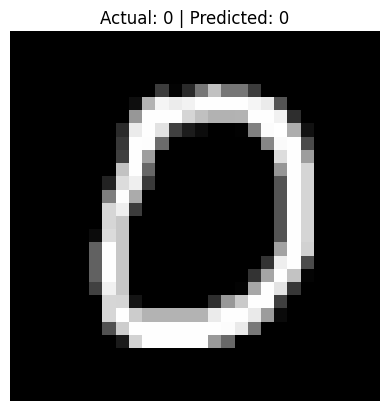

In [ ]:

#Step 23: Predict a Single MNIST Image


image_index = 10

# Select one image
sample_image = x_test_cnn[image_index]

# Model requires a batch dimension
# (28, 28, 1) → (1, 28, 28, 1)
input_image = np.expand_dims(
    sample_image,
    axis=0
)

# Generate probabilities for all 10 classes
probabilities = improved_cnn_model.predict(
    input_image,
    verbose=0
)

# Find the class with the highest probability
predicted_digit = np.argmax(
    probabilities[0]
)

confidence = np.max(
    probabilities[0]
)

print("Actual digit:", y_test[image_index])
print("Predicted digit:", predicted_digit)
print(f"Confidence: {confidence * 100:.2f}%")

plt.imshow(
    sample_image.squeeze(),
    cmap="gray"
)

plt.title(
    f"Actual: {y_test[image_index]} | "
    f"Predicted: {predicted_digit}"
)

plt.axis("off")
plt.show()

# Step 25: Display Multiple Predictions

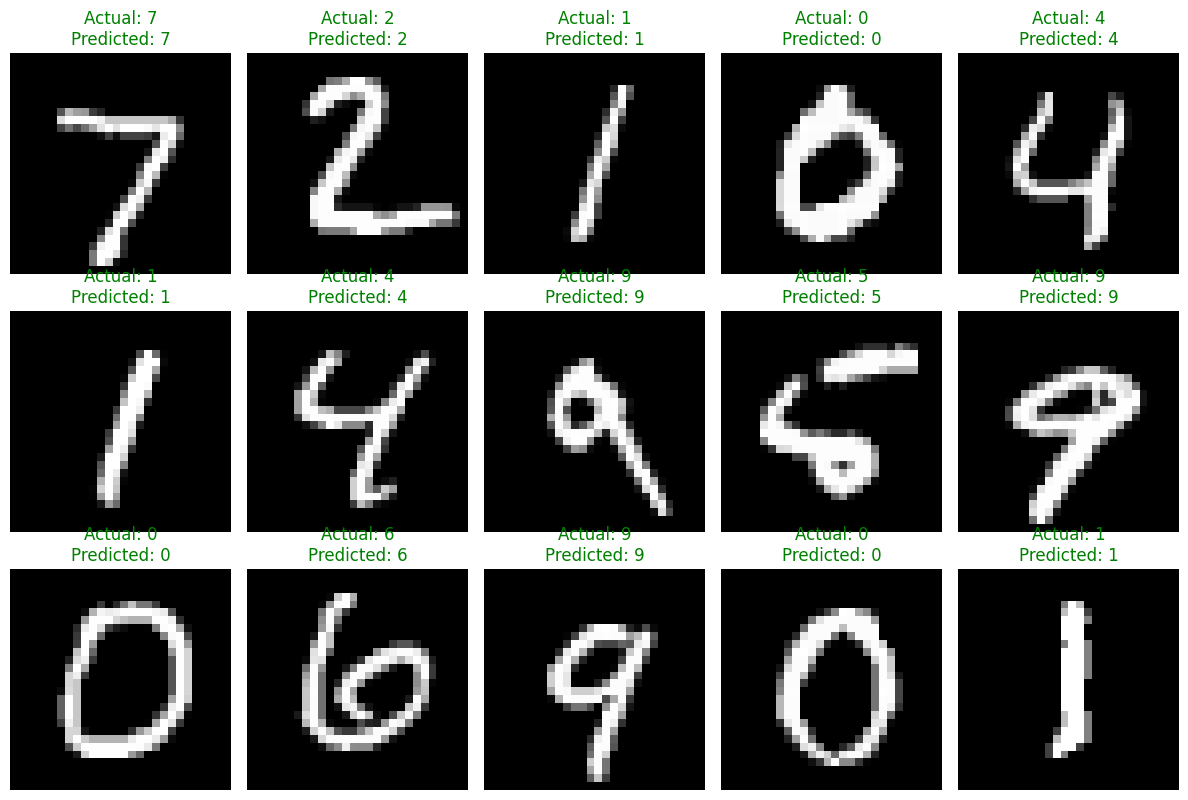

In [ ]:

# Step Display Multiple Predictions


number_of_images = 15

sample_images = x_test_cnn[:number_of_images]
actual_labels = y_test[:number_of_images]

probabilities = improved_cnn_model.predict(
    sample_images,
    verbose=0
)

predictions = np.argmax(
    probabilities,
    axis=1
)

plt.figure(figsize=(12, 8))

for index in range(number_of_images):

    plt.subplot(3, 5, index + 1)

    plt.imshow(
        sample_images[index].squeeze(),
        cmap="gray"
    )

    color = (
        "green"
        if predictions[index] == actual_labels[index]
        else "red"
    )

    plt.title(
        f"Actual: {actual_labels[index]}\n"
        f"Predicted: {predictions[index]}",
        color=color
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

#Step__26 Save the Trained Model

In [ ]:

# Saving the Trained Model


improved_cnn_model.save(
    "mnist_improved_cnn.keras"
)

print("Model saved successfully.")


# Load the Saved Model


loaded_model = tf.keras.models.load_model(
    "mnist_improved_cnn.keras"
)

loaded_loss, loaded_accuracy = loaded_model.evaluate(
    x_test_cnn,
    y_test,
    verbose=0
)

print("Loaded model accuracy:", loaded_accuracy)

Model saved successfully.
Loaded model accuracy: 0.9937999844551086


#Adding information for the revision

In [ ]:
'''
1. Load MNIST images and labels
2. Normalize pixel values
3. Add channel dimension
4. Pass images through convolution layers
5. Filters extract edges and shapes
6. ReLU introduces non-linearity
7. Max pooling reduces feature-map size
8. Batch normalization stabilizes training
9. Dropout controls overfitting
10. Flatten converts feature maps into a vector
11. Dense layer performs classification
12. Softmax produces probabilities for digits 0–9
13. Cross-entropy calculates prediction error
14. Adam updates model weights
15. Test data evaluates final performance

'''''

'\n1. Load MNIST images and labels\n2. Normalize pixel values\n3. Add channel dimension\n4. Pass images through convolution layers\n5. Filters extract edges and shapes\n6. ReLU introduces non-linearity\n7. Max pooling reduces feature-map size\n8. Batch normalization stabilizes training\n9. Dropout controls overfitting\n10. Flatten converts feature maps into a vector\n11. Dense layer performs classification\n12. Softmax produces probabilities for digits 0–9\n13. Cross-entropy calculates prediction error\n14. Adam updates model weights\n15. Test data evaluates final performance\n\n'

In [ ]:
'''

1. ANN
   Main Idea  : Uses flattened pixels
   Advantage  : Simple and fast
   Limitation : Loses spatial structure

2. Basic CNN
   Main Idea  : Learns spatial features using convolution filters
   Advantage  : Provides better image-classification accuracy
   Limitation : Can overfit the training data

3. Improved CNN
   Main Idea  : Uses Batch Normalization and Dropout with CNN layers
   Advantage  : Provides stable training and high accuracy
   Limitation : Requires more computation

4. Augmented CNN
   Main Idea  : Trains on rotated, zoomed and translated images
   Advantage  : Provides better generalization on unseen images
   Limitation : Takes longer to train

   '''

'\n\n1. ANN\n   Main Idea  : Uses flattened pixels\n   Advantage  : Simple and fast\n   Limitation : Loses spatial structure\n\n2. Basic CNN\n   Main Idea  : Learns spatial features using convolution filters\n   Advantage  : Provides better image-classification accuracy\n   Limitation : Can overfit the training data\n\n3. Improved CNN\n   Main Idea  : Uses Batch Normalization and Dropout with CNN layers\n   Advantage  : Provides stable training and high accuracy\n   Limitation : Requires more computation\n\n4. Augmented CNN\n   Main Idea  : Trains on rotated, zoomed and translated images\n   Advantage  : Provides better generalization on unseen images\n   Limitation : Takes longer to train\n\n   '

**Thanks__________for___________patience**